# 01 - Returns

Week 1 of the roadmap (markets & instruments).

Plan for this notebook:
- download 10 years of daily data for 10 assets
- compute simple and log returns
- check that sum of log returns = log of the gross return
- look at adjusted vs unadjusted prices

Data is from yfinance. I also wanted Stooq to cross check, but stooq.com blocks scripted downloads now (it shows a javascript browser check), so I'll download those csv files by hand and compare at the end.

In [1]:
import sys
sys.path.append('../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data import get_data, load_stooq
import returns as rt

%matplotlib inline
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

## Assets

Tried to pick assets that are different from each other: ETFs, single stocks (with splits), gold, bonds, bitcoin (trades every day), one PSX stock and the USD/PKR rate.

For Pakistan I wanted the KSE-100 index, but `^KSE` doesn't return anything on yahoo anymore. Using OGDC (big KSE-100 company) for now.

In [2]:
tickers = {
    'SPY': 'SPY',         # S&P 500 ETF
    'EFA': 'EFA',         # developed markets ex US
    'EEM': 'EEM',         # emerging markets
    'TLT': 'TLT',         # 20+ year treasuries
    'GLD': 'GLD',         # gold
    'AAPL': 'AAPL',       # split 4:1 in 2020
    'NVDA': 'NVDA',       # splits 4:1 (2021) and 10:1 (2024)
    'BTC': 'BTC-USD',     # 365 days a year
    'OGDC': 'OGDC.KA',    # PSX, in PKR
    'USDPKR': 'PKR=X',    # PKR per 1 USD
}

start = '2016-11-01'
end = '2026-11-01'   # end date is not included

In [3]:
data = {}
for name, t in tickers.items():
    data[name] = get_data(t, start, end)
    print(name, data[name].shape, data[name].index[0].date(), data[name].index[-1].date())

SPY (2513, 9) 2016-11-01 2026-10-30
EFA (2513, 9) 2016-11-01 2026-10-30
EEM (2513, 9) 2016-11-01 2026-10-30
TLT (2513, 9) 2016-11-01 2026-10-30
GLD (2513, 9) 2016-11-01 2026-10-30
AAPL (2513, 8) 2016-11-01 2026-10-30
NVDA (2513, 8) 2016-11-01 2026-10-30
BTC (3652, 8) 2016-11-01 2026-10-31
OGDC (2588, 9) 2016-11-01 2026-10-30
USDPKR (2601, 8) 2016-11-01 2026-10-30


In [4]:
data['SPY'].head()

,Adj Close,Capital Gains,Close,Dividends,High,Low,Open,Stock Splits,Volume
Date,,,,,,,,,
2016-11-01,180.201614,0.0,211.009995,0.0,212.990005,209.600006,212.929993,0.0,122781800
2016-11-02,179.117035,0.0,209.740005,0.0,211.100006,209.229996,210.649994,0.0,103330800
2016-11-03,178.297119,0.0,208.779999,0.0,210.240005,208.460007,209.990005,0.0,88939300
2016-11-04,178.100739,0.0,208.550003,0.0,209.889999,208.380005,208.910004,0.0,109122100
2016-11-07,182.029144,0.0,213.149994,0.0,213.190002,208.550003,208.550003,0.0,109794900


`Close` is only adjusted for splits, `Adj Close` is adjusted for splits and dividends. For returns I'll use `Adj Close` (total return).

Every file I download is saved in `data/raw/` and logged in `data/MANIFEST.csv` with a sha256 hash, so I can tell later if the data changed.

In [5]:
pd.read_csv('../data/MANIFEST.csv')[['symbol', 'rows', 'first_date', 'last_date', 'sha256']]

,symbol,rows,first_date,last_date,sha256
0,AAPL,2513,2016-11-01,2026-10-30,6df0b6d32fa2bf355d4dc49f8b0a63a95ece9bc47c0e41...
1,BTC-USD,3652,2016-11-01,2026-10-31,042ecac20d64c46b00d990bc81cf1f23b730cbafe31d7d...
2,EEM,2513,2016-11-01,2026-10-30,08d7355cbce4e31febc0975959c637eb69df294ecd3339...
3,EFA,2513,2016-11-01,2026-10-30,b5df011e7f8d6dc4850b4f5a37f745ad20ac355a912594...
4,GLD,2513,2016-11-01,2026-10-30,1ea6d7e902d694f88d77f65f014f42dacde47fe0f9a3aa...
5,NVDA,2513,2016-11-01,2026-10-30,057faff41d018924a6bdd7b6b5a9cf3af6d10408b60a1f...
6,OGDC.KA,2588,2016-11-01,2026-10-30,cf220a5ab5f9e3d2db0b0ac47ad90cd697737de86468c0...
7,PKR=X,2601,2016-11-01,2026-10-30,29801585242cd3f2c525c492c1ea3e5c7af323032a9f58...
8,SPY,2513,2016-11-01,2026-10-30,6ee5c16185ffbe1f148fc48c981ef35b51c646ce51bd76...
9,TLT,2513,2016-11-01,2026-10-30,88475de15af424ec11650bcdf5630e1d7c9d2cba2fc712...


## Checking the data first

Things to look for before computing returns: missing values, prices <= 0, days with zero volume, days where the price didn't move, and very big moves.

In [6]:
checks = []
for name, df in data.items():
    ret = df['Adj Close'].pct_change()
    checks.append({
        'asset': name,
        'rows': len(df),
        'missing': df['Adj Close'].isna().sum(),
        'price <= 0': (df['Adj Close'] <= 0).sum(),
        'zero volume': (df['Volume'] == 0).sum(),
        'zero return days': (ret == 0).sum(),
        'moves > 10%': (ret.abs() > 0.10).sum(),
        'splits': (df['Stock Splits'] > 0).sum(),
        'dividends': (df['Dividends'] > 0).sum(),
    })

checks = pd.DataFrame(checks).set_index('asset')
checks

,rows,missing,price <= 0,zero volume,zero return days,moves > 10%,splits,dividends
asset,,,,,,,,
SPY,2513,0,0,0,5,2,0,40
EFA,2513,0,0,0,19,2,0,21
EEM,2513,0,0,0,17,2,0,21
TLT,2513,0,0,0,9,0,0,120
GLD,2513,0,0,0,8,1,0,0
AAPL,2513,0,0,0,6,5,1,40
NVDA,2513,0,0,0,3,20,2,40
BTC,3652,0,0,0,1,84,0,0
OGDC,2588,0,0,132,138,3,0,40


OGDC has 132 days with zero volume. USDPKR has zero volume on every day, but that's normal for FX (no volume data). Looking at OGDC:

In [7]:
ogdc = data['OGDC']
ogdc[ogdc['Volume'] == 0][['Close', 'Volume']].head(10)

,Close,Volume
Date,,
2016-11-09,142.059998,0
2016-12-12,156.380005,0
2017-03-23,146.800003,0
2017-04-05,150.059998,0
2017-05-01,154.380005,0
2017-06-23,139.809998,0
2017-06-26,139.809998,0
2017-06-27,139.809998,0
2017-06-28,139.809998,0


In [8]:
ogdc.loc['2025-12-29':'2026-01-02', ['Close', 'Volume']]

,Close,Volume
Date,,
2025-12-29,273.570007,4284099
2025-12-30,280.709991,8989260
2025-12-31,281.089996,5922492
2026-01-01,281.089996,0
2026-01-02,294.239990,11018046


These are PSX holidays (1 Jan, 25 Dec, Eid etc). Yahoo just repeats the previous close with volume 0. If I keep them I get fake 0% days, which makes volatility look lower than it is. So I'll drop them.

Now USD/PKR. The biggest daily moves:

In [9]:
fx = data['USDPKR']
fx_ret = fx['Close'].pct_change()
fx_ret.abs().sort_values(ascending=False).head(8)

Date
2022-08-02    0.156469
2022-08-01    0.138183
2023-01-27    0.087429
2018-10-11    0.080146
2023-01-31    0.079663
2022-09-20    0.079580
2022-09-19    0.065264
2023-03-03    0.062967
Name: Close, dtype: float64

In [10]:
fx.loc['2022-07-28':'2022-08-03', ['Open', 'High', 'Low', 'Close']]

,Open,High,Low,Close
Date,,,,
2022-07-28,233.871506,236.979630,206.750000,235.250000
2022-07-29,235.412338,237.542618,206.750000,239.899994
2022-08-01,237.659973,237.659973,237.036407,206.750000
2022-08-02,236.199722,239.100006,236.199722,239.100006
2022-08-03,238.079010,238.300003,226.025421,238.300003


On 2022-08-01 the close is 206.75 but the low of the day is 237.04, so the close is below the low, which can't happen. Next day it jumps back to 239. That's a bad tick (-14% and then +16%).

How often is the close outside the high-low range?

In [11]:
outside = (fx['Close'] > fx['High'] * 1.001) | (fx['Close'] < fx['Low'] * 0.999)
print(outside.sum(), 'rows out of', len(fx), f'({outside.mean():.0%})')

fx.loc['2026-10-20':'2026-10-30', ['Open', 'High', 'Low', 'Close']]

528 rows out of 2601 (20%)


,Open,High,Low,Close
Date,,,,
2026-10-20,268.213898,276.600006,268.015778,267.945129
2026-10-21,267.618347,268.251038,267.618347,276.450012
2026-10-22,268.150757,268.349060,268.150757,268.251038
2026-10-23,267.984283,268.073700,267.984283,276.450012
2026-10-26,267.417999,268.067230,267.417999,267.860748
2026-10-27,268.636017,268.636017,267.872498,276.750000
2026-10-28,268.505829,268.505829,267.807678,276.750000
2026-10-29,267.507416,276.399994,267.507416,276.399994
2026-10-30,267.998688,267.998688,267.998688,276.399994


20% of the rows! And in Oct 2026 the close keeps jumping between ~268 and ~276.5. Looks like yahoo mixes two different price sources for PKR. So the open/high/low columns are not reliable here and I can't use them to filter.

What I'll do instead: remove prices that are more than 1.5% away from the 5-day rolling median (centered). Not perfect, but it removes the obvious spikes.
(Note: a centered window uses the next 2 days, which is fine for cleaning history but would be look-ahead in a backtest.)

In [12]:
def remove_spikes(s, thresh=0.015):
    s = s.dropna()
    for i in range(3):   # repeat a few times, removing one spike can reveal another
        med = s.rolling(5, center=True, min_periods=3).median()
        bad = np.abs(np.log(s / med)) > thresh
        s = s[~bad]
    return s

fx_clean = remove_spikes(fx['Adj Close'])
print('removed', len(fx) - len(fx_clean), 'rows')

removed 64 rows


Clean prices for each asset. Every asset keeps its own calendar (I'm not joining them into one table, because then the holidays become NaN).

In [13]:
prices = {}
for name, df in data.items():
    p = df['Adj Close']
    if name == 'OGDC':
        p = p[df['Volume'] > 0]
    if name == 'USDPKR':
        p = fx_clean
    prices[name] = p.dropna()

checks['rows used'] = [len(prices[n]) for n in checks.index]
checks.to_csv('../data/quality_log.csv')
checks[['rows', 'rows used']]

,rows,rows used
asset,,
SPY,2513,2513
EFA,2513,2513
EEM,2513,2513
TLT,2513,2513
GLD,2513,2513
AAPL,2513,2513
NVDA,2513,2513
BTC,3652,3652
OGDC,2588,2456


## Simple vs log returns

- simple: R = P_t / P_(t-1) - 1
- log: r = ln(P_t / P_(t-1)) = ln(1 + R)

In [14]:
simple = {}
logret = {}
for name, p in prices.items():
    simple[name] = rt.simple_returns(p)
    logret[name] = rt.log_returns(p)

spy = pd.DataFrame({'price': prices['SPY'], 'simple': simple['SPY'], 'log': logret['SPY']})
spy['diff'] = spy['log'] - spy['simple']
spy.head(6)

,price,simple,log,diff
Date,,,,
2016-11-01,180.201614,NaN,NaN,NaN
2016-11-02,179.117035,-0.006019,-0.006037,-1.818538e-05
2016-11-03,178.297119,-0.004578,-0.004588,-1.050903e-05
2016-11-04,178.100739,-0.001101,-0.001102,-6.070125e-07
2016-11-07,182.029144,0.022057,0.021817,-2.397414e-04
2016-11-08,182.849014,0.004504,0.004494,-1.011292e-05


For normal days they're almost the same. The difference grows when the move is big:

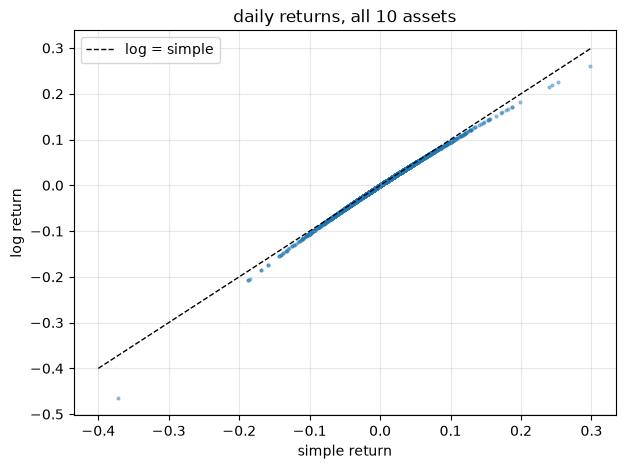

worst day: 2020-03-12  simple = -0.3717  log = -0.4647


In [15]:
all_simple = pd.concat(simple.values())
all_log = pd.concat(logret.values())

plt.figure(figsize=(7, 5))
plt.scatter(all_simple, all_log, s=4, alpha=0.4)
x = np.linspace(-0.4, 0.3, 100)
plt.plot(x, x, 'k--', lw=1, label='log = simple')
plt.xlabel('simple return')
plt.ylabel('log return')
plt.title('daily returns, all 10 assets')
plt.legend()
plt.show()

i = all_simple.values.argmin()
print('worst day:', all_simple.index[i].date(), ' simple =', round(all_simple.iloc[i], 4), ' log =', round(all_log.iloc[i], 4))

Worst day is BTC on 12 March 2020: -37% simple but -46.5% log. Log return is always below the simple return.

## Small example by hand: 100 -> 110 -> 99

In [16]:
p = pd.Series([100, 110, 99])
R = rt.simple_returns(p)
r = rt.log_returns(p)

print('simple returns:', R.values, ' sum =', round(R.sum(), 6))
print('actual total return:', round(99 / 100 - 1, 6))
print('log returns:', r.values.round(6), ' sum =', round(r.sum(), 6))
print('ln(99/100) =', round(np.log(99 / 100), 6))

simple returns: [ 0.1 -0.1]  sum = 0.0
actual total return: -0.01
log returns: [ 0.09531  -0.105361]  sum = -0.01005
ln(99/100) = -0.01005


+10% then -10% adds up to 0, but I actually lost 1%. The log returns add up exactly to ln(99/100).

## Main check: sum of log returns = ln(P_T / P_0)

Why it works: ln(P1/P0) + ln(P2/P1) + ... + ln(PT/PT-1) = ln(PT) - ln(P0), everything in the middle cancels.

In [17]:
rows = []
for name, p in prices.items():
    sum_log = logret[name].sum()
    log_gross = np.log(p.iloc[-1] / p.iloc[0])
    prod_simple = (1 + simple[name]).prod()

    # the check from the roadmap
    assert abs(np.exp(sum_log) / prod_simple - 1) < 1e-10, name
    assert abs(sum_log - log_gross) < 1e-10, name

    rows.append([name, sum_log, log_gross, abs(sum_log - log_gross),
                 p.iloc[-1] / p.iloc[0] - 1, simple[name].sum()])

res = pd.DataFrame(rows, columns=['asset', 'sum log', 'ln(PT/P0)', 'difference',
                                  'total return', 'sum of simple'])
res.set_index('asset')

,sum log,ln(PT/P0),difference,total return,sum of simple
asset,,,,,
SPY,1.433595,1.433595,8.881784e-16,3.193747,1.595310
EFA,0.879949,0.879949,2.442491e-15,1.410778,1.024932
EEM,0.724109,0.724109,3.330669e-15,1.062893,0.942489
TLT,-0.185253,-0.185253,2.248202e-15,-0.169106,-0.075603
GLD,1.064326,1.064326,3.552714e-15,1.898884,1.200676
AAPL,2.603943,2.603943,4.440892e-16,12.516933,3.027707
NVDA,4.794164,4.794164,0.000000e+00,119.803343,6.038907
BTC,4.664430,4.664430,8.881784e-16,105.105083,6.915283
OGDC,1.487506,1.487506,2.220446e-15,3.426042,2.004566


All 10 pass, the difference is ~1e-15 (just floating point error).

The last column is what you get if you add up simple returns, and it's way off. NVDA would show +604% instead of +11,980%, and TLT -7.6% instead of -16.9%.

### When does the check fail?

If I put OGDC and SPY in one dataframe (outer join), OGDC gets NaN on days when the US is open but PSX is closed. pandas `.sum()` skips NaNs without telling you, so the check breaks:

In [18]:
both = pd.concat([prices['SPY'], prices['OGDC']], axis=1, keys=['SPY', 'OGDC'], sort=True)
og = both['OGDC'].loc[prices['OGDC'].index[0]:]

print('NaN days:', og.isna().sum())
print('sum of log returns with NaNs:', round(np.log(og / og.shift(1)).sum(), 4))
print('true ln(PT/P0):', round(np.log(og.iloc[-1] / og.iloc[0]), 4))

og_ff = og.ffill()
print('after ffill:', round(np.log(og_ff / og_ff.shift(1)).sum(), 4), '(passes, but now has fake 0% days)')

NaN days: 141
sum of log returns with NaNs: 1.4257
true ln(PT/P0): 1.4875
after ffill: 1.4875 (passes, but now has fake 0% days)


So the identity is also a nice test for the data pipeline. If it fails, something is wrong with the data, not the maths.

## Across assets it's the other way round

For a portfolio, the simple returns are the ones that add up: R_p = w1*R1 + w2*R2. Averaging log returns is not the same thing. Trying a 50/50 SPY + BTC portfolio, rebalanced daily:

In [19]:
common = simple['SPY'].index.intersection(simple['BTC'].index)
R1 = simple['SPY'][common]
R2 = simple['BTC'][common]

correct = 0.5 * R1 + 0.5 * R2
wrong = np.exp(0.5 * np.log(1 + R1) + 0.5 * np.log(1 + R2)) - 1

print('10y return, correct:', f'{(1 + correct).prod() - 1:.1%}')
print('10y return, averaging log returns:', f'{(1 + wrong).prod() - 1:.1%}')
print('worst daily error (bp):', round((wrong - correct).min() * 10000))

10y return, correct: 1872.1%
10y return, averaging log returns: 1185.7%
worst daily error (bp): -125


The log version is always lower (Jensen's inequality, log is concave). Small per day, but over 10 years it adds up a lot.

## Close vs Adj Close (dividends)

In [20]:
div = pd.DataFrame(index=tickers.keys())
for name, df in data.items():
    keep = prices[name].index
    div.loc[name, 'price return'] = df['Close'][keep].iloc[-1] / df['Close'][keep].iloc[0] - 1
    div.loc[name, 'total return'] = prices[name].iloc[-1] / prices[name].iloc[0] - 1

div['from dividends'] = div['total return'] - div['price return']
div.round(3)

,price return,total return,from dividends
SPY,2.581,3.194,0.612
EFA,0.796,1.411,0.615
EEM,0.657,1.063,0.406
TLT,-0.375,-0.169,0.206
GLD,1.899,1.899,0.000
AAPL,11.365,12.517,1.152
NVDA,117.546,119.803,2.257
BTC,105.105,105.105,0.000
OGDC,1.144,3.426,2.283
USDPKR,1.640,1.640,0.000


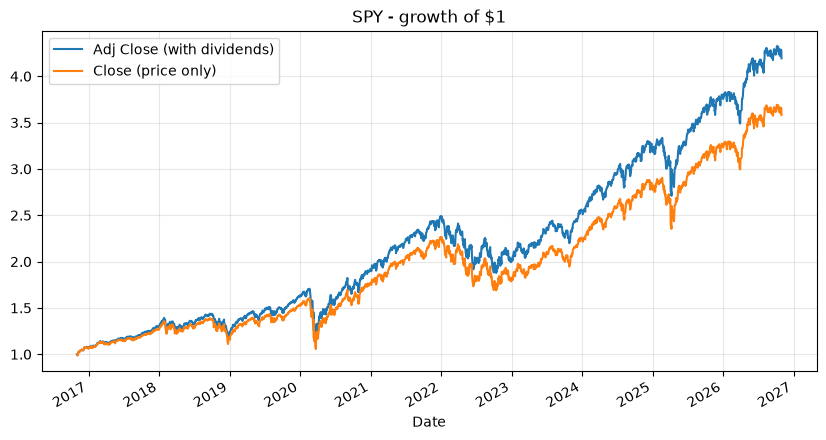

In [21]:
s = data['SPY']
(s['Adj Close'] / s['Adj Close'].iloc[0]).plot(label='Adj Close (with dividends)')
(s['Close'] / s['Close'].iloc[0]).plot(label='Close (price only)')
plt.title('SPY - growth of $1')
plt.legend()
plt.show()

TLT: price fell 37.5% but with the monthly payouts the loss is only 16.9%. OGDC: +114% price only, +343% with dividends. GLD, BTC and USDPKR don't pay anything so both columns are the same.

## Splits

Yahoo's `Close` is already split adjusted. To see the real prices that traded on the exchange I have to undo the splits: multiply each price by all the split ratios that come after that date.

In [22]:
nv = data['NVDA']
splits = nv['Stock Splits'][nv['Stock Splits'] > 0]
print(splits)

factor = pd.Series(1.0, index=nv.index)
for date, ratio in splits.items():
    factor[nv.index < date] *= ratio

nv_raw = nv['Close'] * factor

Date
2021-07-20     4.0
2024-06-10    10.0
Name: Stock Splits, dtype: float64


In [23]:
raw_ret = nv_raw.pct_change()
adj_ret = nv['Adj Close'].pct_change()
pd.DataFrame({'raw price return': raw_ret[splits.index], 'adjusted return': adj_ret[splits.index]})

,raw price return,adjusted return
Date,,
2021-07-20,-0.752233,-0.008932
2024-06-10,-0.899254,0.007461


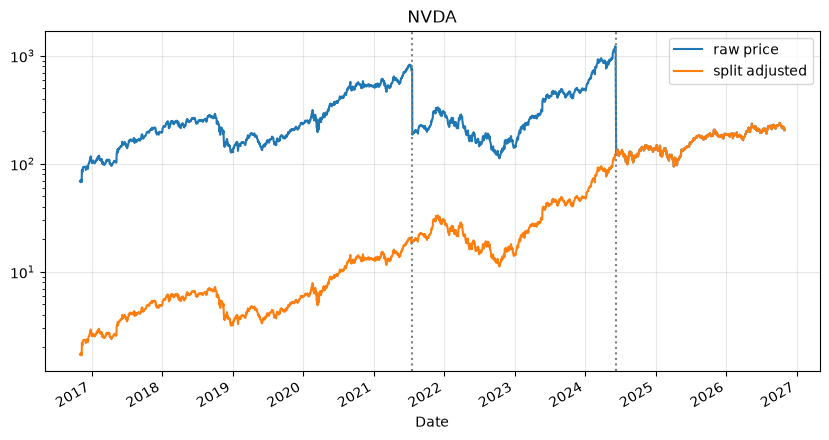

In [24]:
nv_raw.plot(label='raw price', logy=True)
nv['Close'].plot(label='split adjusted', logy=True)
for d in splits.index:
    plt.axvline(d, color='gray', ls=':')
plt.title('NVDA')
plt.legend()
plt.savefig('../figures/nvda_splits.png', dpi=120, bbox_inches='tight')
plt.show()

With raw prices it looks like NVDA crashed 75% and then 90%, but the real returns on those days were -0.9% and +0.75%. A split just changes the number of shares, not what you own.

## Growth of 1 and some stats

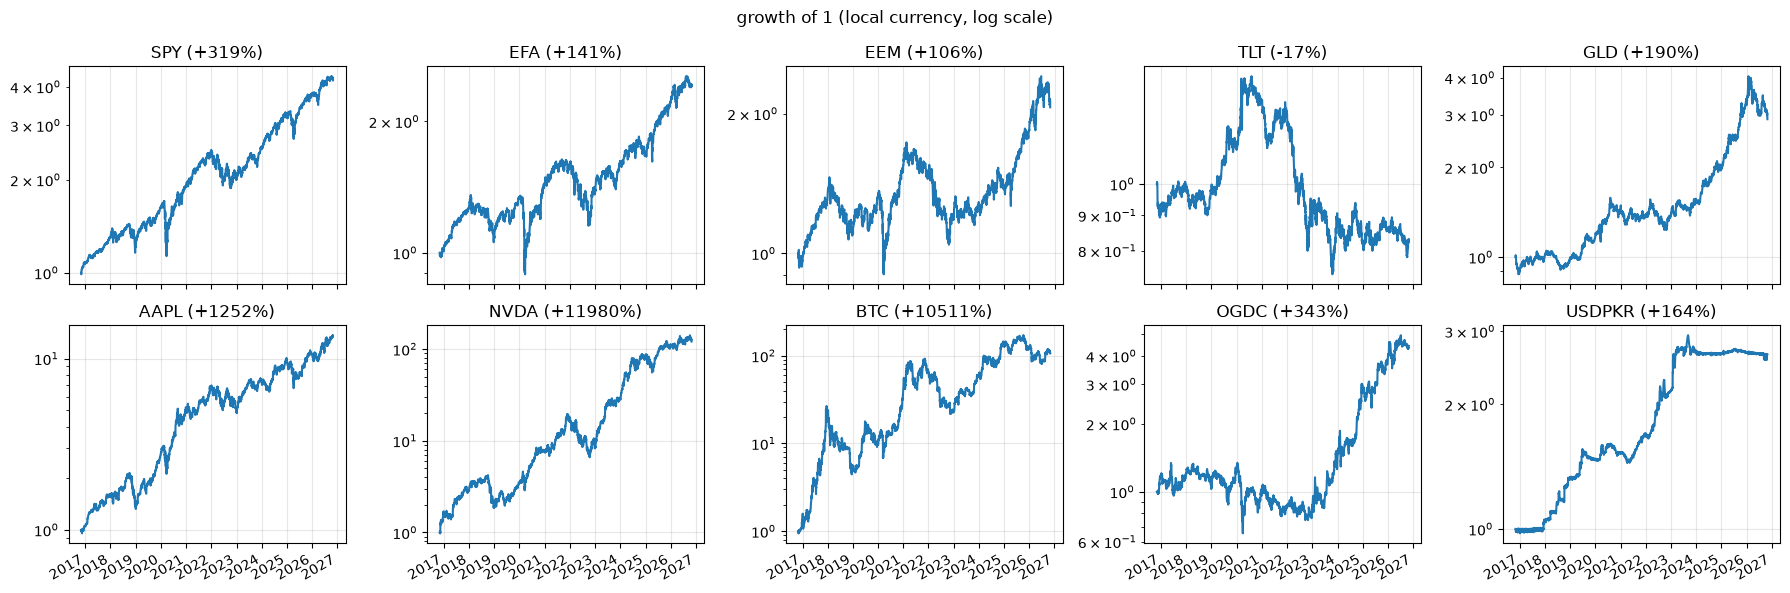

In [25]:
fig, axes = plt.subplots(2, 5, figsize=(18, 6))
for ax, name in zip(axes.flatten(), prices):
    p = prices[name]
    ax.plot(p.index, p / p.iloc[0])
    ax.set_yscale('log')
    ax.set_title(f'{name} ({p.iloc[-1] / p.iloc[0] - 1:+.0%})')
fig.autofmt_xdate()
plt.suptitle('growth of 1 (local currency, log scale)')
plt.tight_layout()
plt.savefig('../figures/growth_of_1.png', dpi=120, bbox_inches='tight')
plt.show()

For annualizing I use the actual number of observations per year for each asset instead of 252 everywhere. BTC trades 365 days, so with 252 its volatility comes out too low (by sqrt(365/252) = 1.2x).

In [26]:
stats = pd.DataFrame(index=prices.keys())
for name, p in prices.items():
    ppy = rt.periods_per_year(p.index)
    stats.loc[name, 'obs/year'] = round(ppy)
    stats.loc[name, 'ann. return'] = rt.annualized_return(simple[name], ppy)
    stats.loc[name, 'ann. vol'] = rt.annualized_vol(logret[name], ppy)
    stats.loc[name, 'vol with 252'] = rt.annualized_vol(logret[name], 252)
    stats.loc[name, 'max drawdown'] = rt.max_drawdown(p)
    stats.loc[name, 'worst day'] = simple[name].min()

stats.round(3)

,obs/year,ann. return,ann. vol,vol with 252,max drawdown,worst day
SPY,251.0,0.154,0.180,0.180,-0.337,-0.109
EFA,251.0,0.092,0.171,0.171,-0.342,-0.110
EEM,251.0,0.075,0.209,0.210,-0.398,-0.125
TLT,251.0,-0.018,0.148,0.148,-0.484,-0.067
GLD,251.0,0.112,0.165,0.165,-0.283,-0.103
AAPL,251.0,0.298,0.291,0.291,-0.385,-0.129
NVDA,251.0,0.616,0.497,0.498,-0.663,-0.188
BTC,365.0,0.595,0.672,0.558,-0.834,-0.372
OGDC,246.0,0.161,0.321,0.325,-0.514,-0.100
USDPKR,254.0,0.102,0.113,0.112,-0.128,-0.044


Also checked the USD/PKR volatility by year, because of the data problems above:

In [27]:
fx_vol = logret['USDPKR'].groupby(logret['USDPKR'].index.year).std() * np.sqrt(260)
fx_level = prices['USDPKR'].groupby(prices['USDPKR'].index.year).agg(['min', 'max'])
fx_level['vol'] = fx_vol
fx_level.round(2)

,min,max,vol
Date,,,
2016,102.65,104.92,0.14
2017,102.15,110.25,0.14
2018,108.57,139.15,0.15
2019,137.60,163.00,0.12
2020,152.96,168.15,0.08
2021,151.14,178.02,0.07
2022,172.95,239.50,0.12
2023,225.22,307.00,0.17
2024,274.53,281.50,0.07


In 2016-17 the rupee was basically fixed around 105 (min/max barely move) but the vol still shows ~14%. That's noise in the yahoo data, not real risk. So yahoo's USD/PKR is OK for the 10 year change but not for volatility. For that I should use the SBP rates (week 6).

### OGDC in PKR vs in USD

OGDC total return in PKR: 343%
OGDC total return in USD: 68%


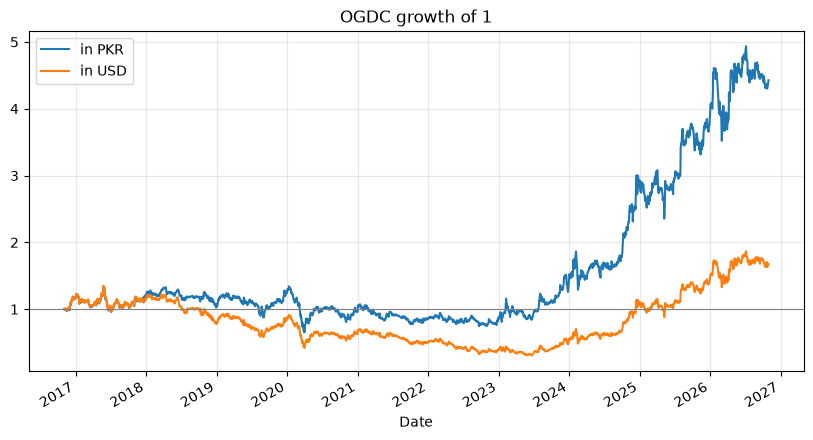

In [28]:
og_pkr = prices['OGDC']
fx_on_psx_days = prices['USDPKR'].reindex(og_pkr.index, method='ffill')   # last known rate, no future data
og_usd = (og_pkr / fx_on_psx_days).dropna()
og_pkr = og_pkr[og_usd.index]

print('OGDC total return in PKR:', f'{og_pkr.iloc[-1] / og_pkr.iloc[0] - 1:.0%}')
print('OGDC total return in USD:', f'{og_usd.iloc[-1] / og_usd.iloc[0] - 1:.0%}')

(og_pkr / og_pkr.iloc[0]).plot(label='in PKR')
(og_usd / og_usd.iloc[0]).plot(label='in USD')
plt.axhline(1, color='gray', lw=0.8)
plt.title('OGDC growth of 1')
plt.legend()
plt.show()

Same shares, but in dollars most of the gain is gone because the rupee went from ~105 to ~275 per dollar.

## Compare with Stooq

Stooq csvs need to be downloaded by hand from the browser (stooq.com/q/d/?s=spy.us, "Download data in csv file") and saved in `data/raw/stooq/`.

In [29]:
stooq_symbols = {'SPY': 'spy.us', 'EFA': 'efa.us', 'EEM': 'eem.us', 'TLT': 'tlt.us', 'GLD': 'gld.us',
                 'AAPL': 'aapl.us', 'NVDA': 'nvda.us', 'BTC': 'btcusd', 'USDPKR': 'usdpkr'}

found = 0
for name, sym in stooq_symbols.items():
    st = load_stooq(sym)
    if st is None:
        continue
    found += 1
    yf_df = data[name]
    common = yf_df.index.intersection(st.index)
    r_st = st['Close'][common].pct_change()
    diff_adj = (r_st - yf_df['Adj Close'][common].pct_change()).abs().median() * 10000
    diff_close = (r_st - yf_df['Close'][common].pct_change()).abs().median() * 10000
    print(f'{name}: {len(common)} common days, median diff vs Adj Close {diff_adj:.2f} bp, vs Close {diff_close:.2f} bp')

if found == 0:
    print('no stooq files yet')

no stooq files yet


## Self check questions

**Why do log returns add over time?**
Because ln(a*b) = ln(a) + ln(b). The total gross return is a product of daily gross returns, and the log turns the product into a sum.

**Why can't I average log returns across assets?**
Portfolio value is a sum of the positions, so the portfolio return is the weighted average of simple returns. Log of a sum isn't the sum of logs.

**What could make annualized volatility misleading?**
Using 252 for an asset that trades 365 days (BTC) or ~246 (PSX), stale/filled prices (fake 0% days), autocorrelated returns (sqrt(T) scaling assumes independence), fat tails, or one crisis dominating a short sample.

**How could my data be wrong?**
I found some in this notebook: PSX holidays filled with old prices, bad USD/PKR ticks and two mixed price sources, and no KSE-100 on yahoo. Other things to watch: delisted stocks are missing (survivorship bias), and Adj Close changes every time a new dividend is paid (that's why I keep the hash in the manifest).